# 15 — MURA all-anatomy baseline vs fine-tuned model comparison

The comparison is paired within each anatomy: both models predict the same internal-validation studies. Each model uses its own threshold selected on internal validation to meet the fixed 95% sensitivity target.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

def locate_project_root():
    for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (candidate / "CHARTER.md").exists():
            return candidate
    raise RuntimeError("Run this notebook from inside the repository checkout.")

ROOT = locate_project_root()
RUNTIME = ROOT.parent / 'runtime' / 'multianatomy_v1'
FINE = RUNTIME / 'finetuned_all_v1'
COMPARISON = RUNTIME / 'model_comparison_v1'
SHORTCUT = RUNTIME / 'shortcut_audit_v1'
assert ROOT.name == 'mura-wrist-ml-pipeline', ROOT
print('Notebook environment configured; results are loaded from saved development artifacts.')


Notebook environment configured; results are loaded from saved development artifacts.


In [2]:
provenance = json.loads((COMPARISON / 'comparison_provenance.json').read_text(encoding='utf-8'))
assert provenance['official_valid_read'] is False
assert provenance['test_used_for_selection'] is False
display(Markdown('**Comparison scope:** development/internal validation only.'))
display(pd.DataFrame([provenance]))

**Comparison scope:** development/internal validation only.

,scope,evaluation_population,operating_policy,official_valid_read,test_used_for_selection,bootstrap,interpretation
0,development-only paired all-anatomy model comp...,same internal validation studies per anatomy,each model uses its own highest validation thr...,False,False,"{'unit': 'patient', 'replicates': 2000, 'compa...",Confidence intervals are conditional on valida...


,anatomy,model,auroc,auprc,sensitivity,specificity,precision,f1,false_negative,false_positive,flagged_percent
0,XR_ELBOW,Fine-tuned ResNet-18,0.9083,0.8935,0.9538,0.4140,0.4960,0.6526,6,126,72.4638
1,XR_ELBOW,Frozen ResNet-18 + Logistic Regression,0.8550,0.8367,0.9538,0.2651,0.4397,0.6019,6,158,81.7391
2,XR_FINGER,Fine-tuned ResNet-18,0.8570,0.7346,0.9535,0.3992,0.4377,0.6000,6,158,71.6837
3,XR_FINGER,Frozen ResNet-18 + Logistic Regression,0.7465,0.6010,0.9535,0.2053,0.3705,0.5336,6,209,84.6939
4,XR_FOREARM,Fine-tuned ResNet-18,0.8438,0.7239,0.9636,0.3359,0.3841,0.5492,2,85,75.4098
5,XR_FOREARM,Frozen ResNet-18 + Logistic Regression,0.8439,0.6861,0.9636,0.3672,0.3955,0.5608,2,81,73.2240
6,XR_HAND,Fine-tuned ResNet-18,0.7924,0.6537,0.9533,0.2763,0.3168,0.4755,5,220,78.3455
7,XR_HAND,Frozen ResNet-18 + Logistic Regression,0.7123,0.5833,0.9533,0.0724,0.2656,0.4155,5,282,93.4307
8,XR_HUMERUS,Fine-tuned ResNet-18,0.8785,0.8750,0.9636,0.4127,0.5889,0.7310,2,37,76.2712
9,XR_HUMERUS,Frozen ResNet-18 + Logistic Regression,0.7948,0.7243,0.9636,0.4921,0.6235,0.7571,2,32,72.0339


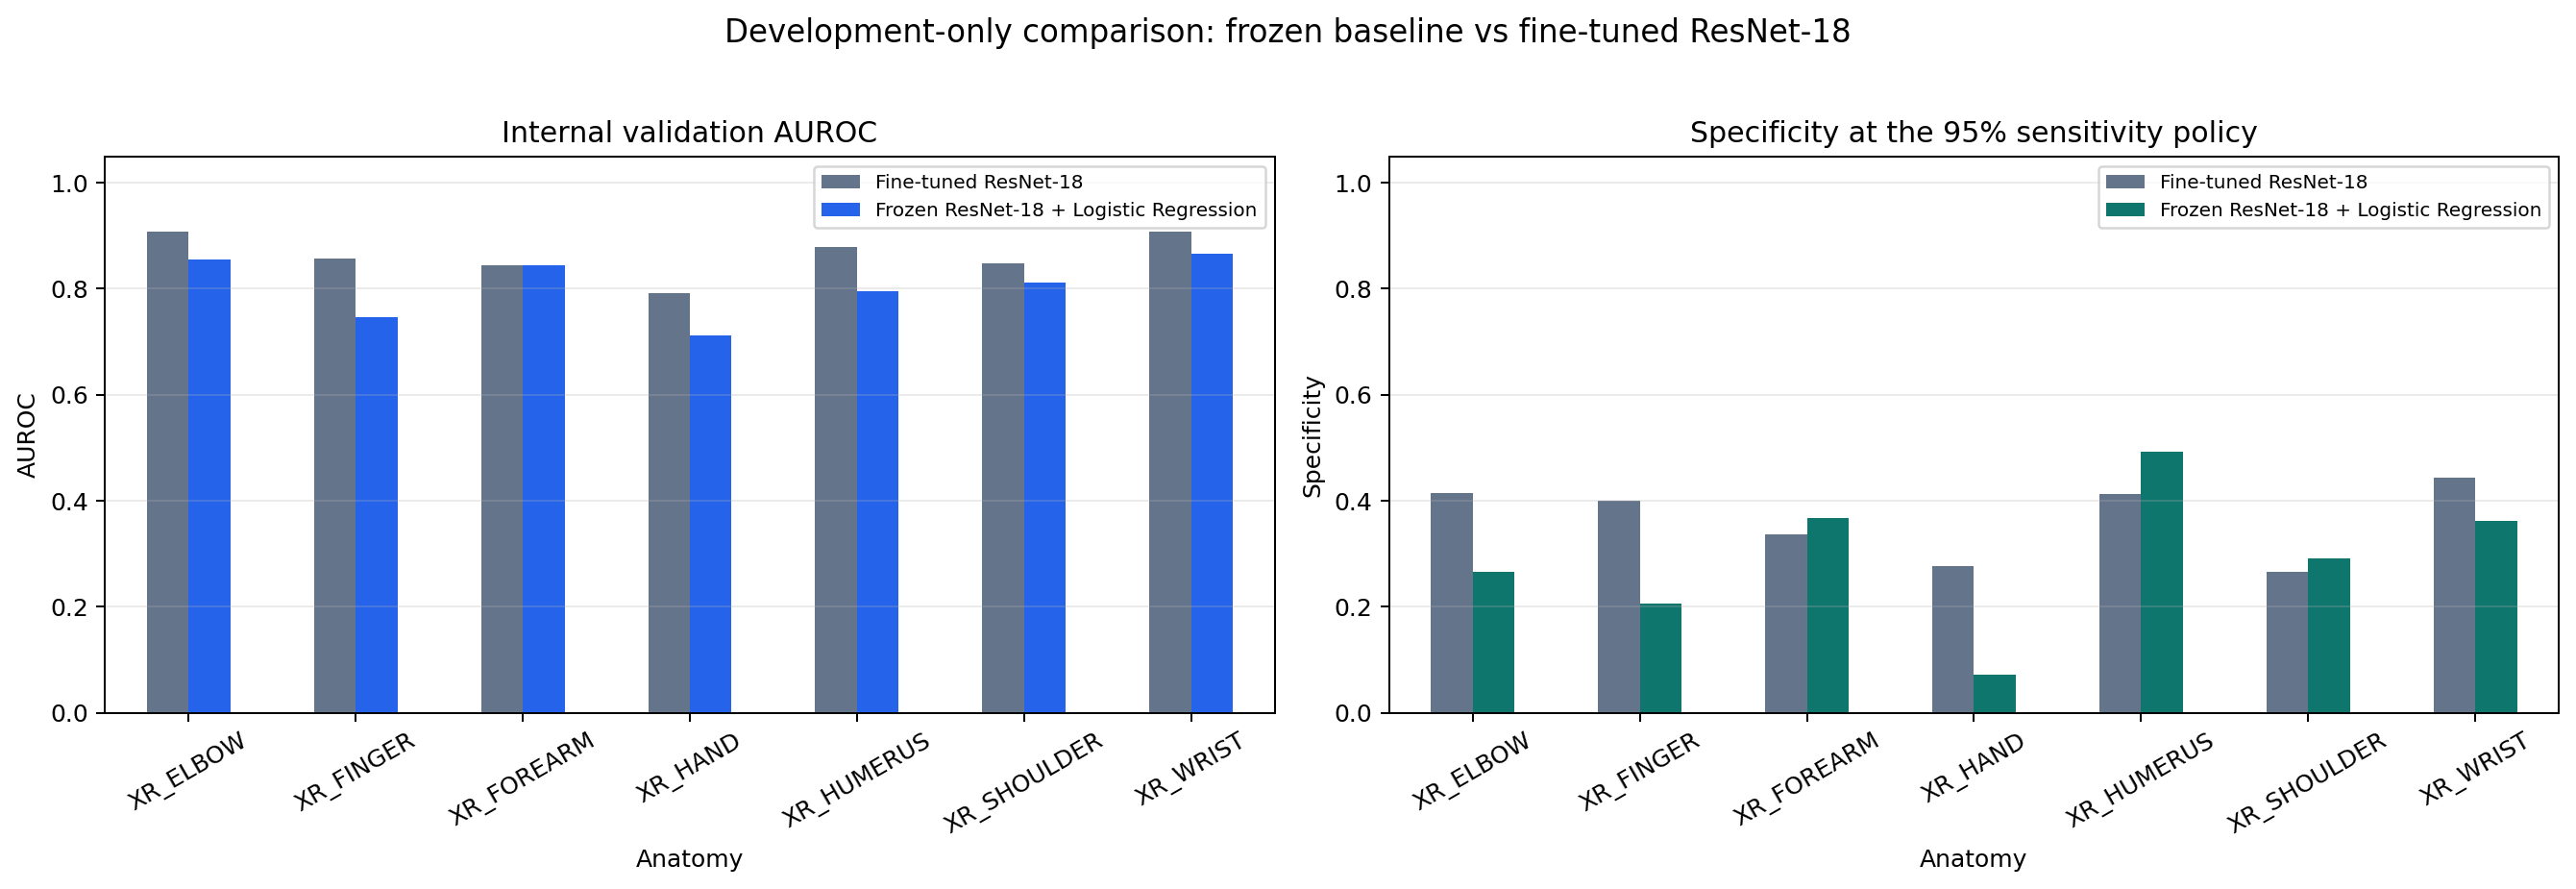

In [3]:
comparison = pd.read_csv(COMPARISON / 'model_comparison_by_anatomy.csv')
display(comparison[[
    'anatomy', 'model', 'auroc', 'auprc', 'sensitivity', 'specificity',
    'precision', 'f1', 'false_negative', 'false_positive', 'flagged_percent'
]].round(4))
display(Image(filename=str(COMPARISON / 'baseline_vs_finetuned.png')))

In [4]:
paired = pd.read_csv(COMPARISON / 'paired_patient_bootstrap.csv')
key_metrics = paired[paired['metric'].isin(['auroc', 'auprc', 'specificity', 'sensitivity'])]
display(key_metrics[['anatomy', 'metric', 'candidate_minus_baseline', 'lower_95_ci', 'upper_95_ci', 'valid_resamples']].round(4))

,anatomy,metric,candidate_minus_baseline,lower_95_ci,upper_95_ci,valid_resamples
0,XR_ELBOW,auprc,0.0568,0.0101,0.1053,2000
1,XR_ELBOW,auroc,0.0533,0.0147,0.0935,2000
5,XR_ELBOW,sensitivity,0.0000,-0.0365,0.0376,2000
6,XR_ELBOW,specificity,0.1488,0.0619,0.2335,2000
7,XR_FINGER,auprc,0.1336,0.0601,0.2154,2000
8,XR_FINGER,auroc,0.1105,0.0699,0.1518,2000
12,XR_FINGER,sensitivity,0.0000,-0.0397,0.0373,2000
13,XR_FINGER,specificity,0.1939,0.1370,0.2500,2000
14,XR_FOREARM,auprc,0.0378,-0.0587,0.1315,2000
15,XR_FOREARM,auroc,-0.0001,-0.0572,0.0564,2000


In [5]:
errors = pd.read_csv(COMPARISON / 'paired_error_summary.csv')
display(errors)

,anatomy,both_correct,both_incorrect,errors_fixed_by_finetuning,errors_introduced_by_finetuning,false_negatives_fixed,false_negatives_introduced
0,XR_ELBOW,149,100,64,32,3,3
1,XR_FINGER,164,151,64,13,3,3
2,XR_FOREARM,73,60,23,27,1,1
3,XR_HAND,112,213,74,12,2,2
4,XR_HUMERUS,67,22,12,17,2,2
5,XR_SHOULDER,305,161,47,54,11,11
6,XR_WRIST,358,197,94,59,8,8


### Interpretation boundary

A point estimate alone is not enough to say that fine-tuning wins. The paired bootstrap interval must be considered, especially for the smaller Humerus and Forearm validation samples. All intervals are conditional on validation-selected thresholds, so they are not a replacement for an untouched final test.